# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---


# Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the notebook before beginning Phase 2.

Declaration: I completed this version without generative AI.

Student(s): Nithya Gopal, Jacob Khaykin, Heidi Williams

Date: 11/16/2026

0
100 0.149 0.135
101 -0.104 0.079
102 0.183 0.27
103 0.192 0.315
104 0.068 0.107
                            100    101    102    103    104
age                       0.232  0.194  0.146  0.235  0.234
anaemia                   0.000  0.000  0.000  0.000  0.000
creatinine_phosphokinase  0.053  0.025  0.031  0.000  0.000
diabetes                  0.000  0.000  0.000  0.000  0.000
ejection_fraction         0.182  0.355  0.393  0.226  0.369
high_blood_pressure       0.033  0.011  0.029  0.055  0.000
platelets                 0.065  0.047  0.149  0.110  0.048
serum_creatinine          0.382  0.360  0.168  0.374  0.250
serum_sodium              0.038  0.008  0.084  0.000  0.027
sex                       0.000  0.000  0.000  0.000  0.071
smoking                   0.014  0.000  0.000  0.000  0.000


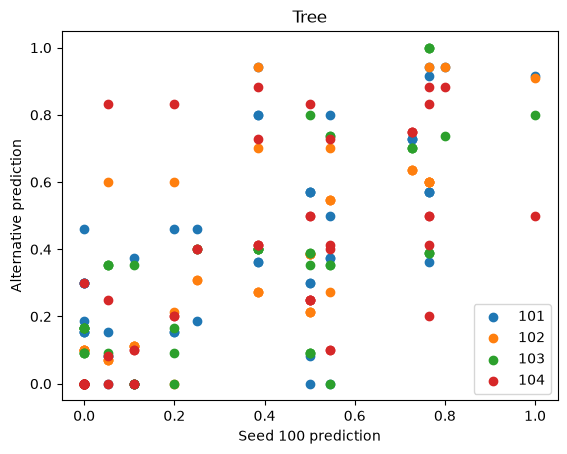

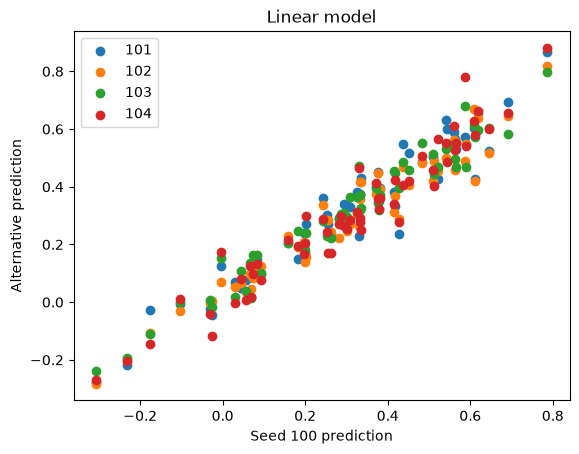

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression

df = pd.read_csv("./data/heart_failure/heart_failure_clinical_records_dataset.csv")
print(df.isnull().sum().sum())
df = df.drop(columns="time")
for v in ["creatinine_phosphokinase", "serum_creatinine", "platelets"]:
    df[v] = np.arcsinh(df[v])
y = df["DEATH_EVENT"]
X = df.drop(columns="DEATH_EVENT")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=100)
tree = DecisionTreeRegressor(min_samples_leaf=10, random_state=100).fit(X_train, y_train)
lm = LinearRegression().fit(X_train, y_train)
print(100, round(tree.score(X_test, y_test), 3), round(lm.score(X_test, y_test), 3))
tree_hat, lm_hat = tree.predict(X_test), lm.predict(X_test)

importance, coefs, tree_preds, lm_preds = {100: tree.feature_importances_}, {100: lm.coef_}, {}, {}
for s in [101, 102, 103, 104]:
    Xs_train, Xs_test, ys_train, ys_test = train_test_split(X, y, test_size=0.2, random_state=s)
    t = DecisionTreeRegressor(min_samples_leaf=10, random_state=s).fit(Xs_train, ys_train)
    m = LinearRegression().fit(Xs_train, ys_train)
    print(s, round(t.score(Xs_test, ys_test), 3), round(m.score(Xs_test, ys_test), 3))
    importance[s], coefs[s] = t.feature_importances_, m.coef_
    tree_preds[s], lm_preds[s] = t.predict(X_test), m.predict(X_test)
print(pd.DataFrame(importance, index=X.columns).round(3))
pd.DataFrame(coefs, index=X.columns).round(3)
import matplotlib.pyplot as plt

for name, base, preds in [("Tree", tree_hat, tree_preds), ("Linear model", lm_hat, lm_preds)]:
    for s in preds:
        plt.scatter(base, preds[s], label=s)
    plt.xlabel("Seed 100 prediction")
    plt.ylabel("Alternative prediction")
    plt.title(name)
    plt.legend()
    plt.show()

**1.** There are no missing values. I dropped the time variable as the follow-up length depends on whether the patient died, so it leaks the outcome. I also applied arcsinh because  the variables creatinine_phosphokinase, serum_creatinine, and platelets were skewed.

**2.** Seed 100, 80/20 split. The Test R^2 for the tree and linear model are as follows: tree 0.149, linear model 0.135. Clearly, both are weak.

**3.** Seeds 101–104. The Test R^2 ranges from −0.10 to 0.19 for the tree and 0.08 to 0.32 for the linear model. The trees change a lot: the top feature switches between serum_creatinine and ejection_fraction (importance of each ranges about 0.17–0.39). Furthermore, features like platelets, serum_sodium, sex, and creatinine_phosphokinase drop in and out. While at the same time, the linear coefficients are steadier: age, ejection_fraction, and serum_creatinine barely move, though weak ones (platelets, smoking, anaemia, diabetes) change size and sometimes sign.

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [2]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]